# 08 - Interpretabilidad y análisis de errores

Preguntas:
1. **¿En qué se fija la CNN?** Saliencia y Grad-CAM 1D sobre las estrellas del test, comparados con los tránsitos
   que encuentra el BLS: ¿la red mira las mismas caídas o se apoya en otra cosa?
2. **¿Qué features usa el Random Forest?** Importancia por permutación en los folds de validación.
3. **¿Qué planetas se escapan y por qué?** Análisis de falsos negativos y falsos positivos con las predicciones
   fuera de fold de la CV (37 positivos, más informativo que los 5 del test).
4. **¿Hay sesgo por campaña?** Los positivos extra vienen de otras campañas de Kepler: si propiedades ajenas al
   planeta (nivel de flujo, ruido) bastan para separar las clases, los modelos podrían estar usándolas.

La lógica está en `src/interpretability.py`. La CNN se entrena una vez sobre todo el entrenamiento con
`CNN_PARAMS` (cambiar a la mejor configuración de la ablación, notebook 07) y se guarda en `results/` (no se sube a
git: se reentrena si falta, unos minutos).

In [1]:
import sys
sys.path.append('..')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

from src.data import load_train_test
from src.preprocessing import preprocess, robust_std
from src.evaluation import choose_threshold, compute_metrics, repeated_cv, summarize_cv
from src.models_classic import make_random_forest, select_columns
from src.models_cnn import CNNClassifier
from src.interpretability import saliency, grad_cam, smooth, bls_transit_mask, attention_on_transits

pd.set_option('display.width', 200)
ACENTO, TRANSITO, GRIS, TEXTO = '#2a78d6', '#eb6834', '#a3a29d', '#52514e'

CNN_NOMBRE = 'cnn_base'          # configuración de results/07_ablacion/ (para leer su umbral y sus OOF)
CNN_PARAMS = {}                  # parámetros de CNNClassifier de esa configuración
ABL = Path('../results/07_ablacion')

Xtr, ytr, Xte, yte = load_train_test()
Ztr, Zte = preprocess(Xtr), preprocess(Xte)
F_train = pd.read_csv('../results/features_train.csv')
F_test = pd.read_csv('../results/features_test.csv')
cols = select_columns(F_train, 'todas')

In [2]:
# CNN entrenada con todo el entrenamiento (se guarda para no reentrenar)
ruta = Path(f'../results/08_{CNN_NOMBRE}.pt')
cnn = CNNClassifier(epochs=20, **CNN_PARAMS)
if ruta.exists():
    from src.models_cnn import CNN1D
    cnn.net_ = CNN1D(dropout=cnn.dropout)
    cnn.net_.load_state_dict(torch.load(ruta))
    cnn.classes_ = np.array([0, 1])
else:
    cnn.fit(Ztr, ytr)
    torch.save(cnn.net_.state_dict(), ruta)
rf = make_random_forest().fit(F_train[cols].to_numpy(), ytr)

p_cnn = cnn.predict_proba(Zte)[:, 1]
p_rf = rf.predict_proba(F_test[cols].to_numpy())[:, 1]

# Umbrales elegidos en la CV del entrenamiento (nunca en el test)
umbral = {'rf': choose_threshold(ytr, np.load(ABL / 'rf_base_oof.npy'))}
if (ABL / f'{CNN_NOMBRE}_oof.npy').exists():
    umbral['cnn'] = choose_threshold(ytr, np.load(ABL / f'{CNN_NOMBRE}_oof.npy'))
print('umbrales elegidos en CV:', {k: round(v, 3) for k, v in umbral.items()})

def puesto(p):
    return pd.Series(p).rank(ascending=False, method='min').astype(int).to_numpy()

test = pd.DataFrame({'p_cnn': p_cnn, 'puesto_cnn': puesto(p_cnn), 'p_rf': p_rf, 'puesto_rf': puesto(p_rf),
                     'label': yte, 'bls_snr': F_test.bls_snr, 'bls_period': F_test.bls_period,
                     'bls_n_transits': F_test.bls_n_transits})
for m, p in [('cnn', p_cnn), ('rf', p_rf)]:
    if m in umbral:
        print(m, {k: round(v, 3) for k, v in compute_metrics(yte, p, umbral[m]).items()})
test[test.label == 1].round(3)

umbrales elegidos en CV: {'rf': 0.248}
rf {'recall': 0.4, 'precision': 1.0, 'f1': 0.571, 'pr_auc': 0.58}


,p_cnn,puesto_cnn,p_rf,puesto_rf,label,bls_snr,bls_period,bls_n_transits
0,0.869,7,0.029,69,1,16.635,24.649,2
1,0.974,4,0.744,1,1,31.064,3.323,20
2,0.890,6,0.036,52,1,13.295,27.197,2
3,0.985,3,0.169,4,1,158.442,3.058,21
4,0.967,5,0.591,2,1,193.040,4.031,16


## 1. ¿En qué se fija la CNN?

Para cada estrella: la curva preprocesada (gris), las zonas que el BLS marca como tránsito (bandas naranjas) y,
debajo, el Grad-CAM de la CNN (más oscuro = la zona empuja más hacia "con planeta"). Se muestran los 5 planetas del
test y las 3 estrellas sin planeta con mayor puntaje de la CNN (sus falsos positivos más fuertes).

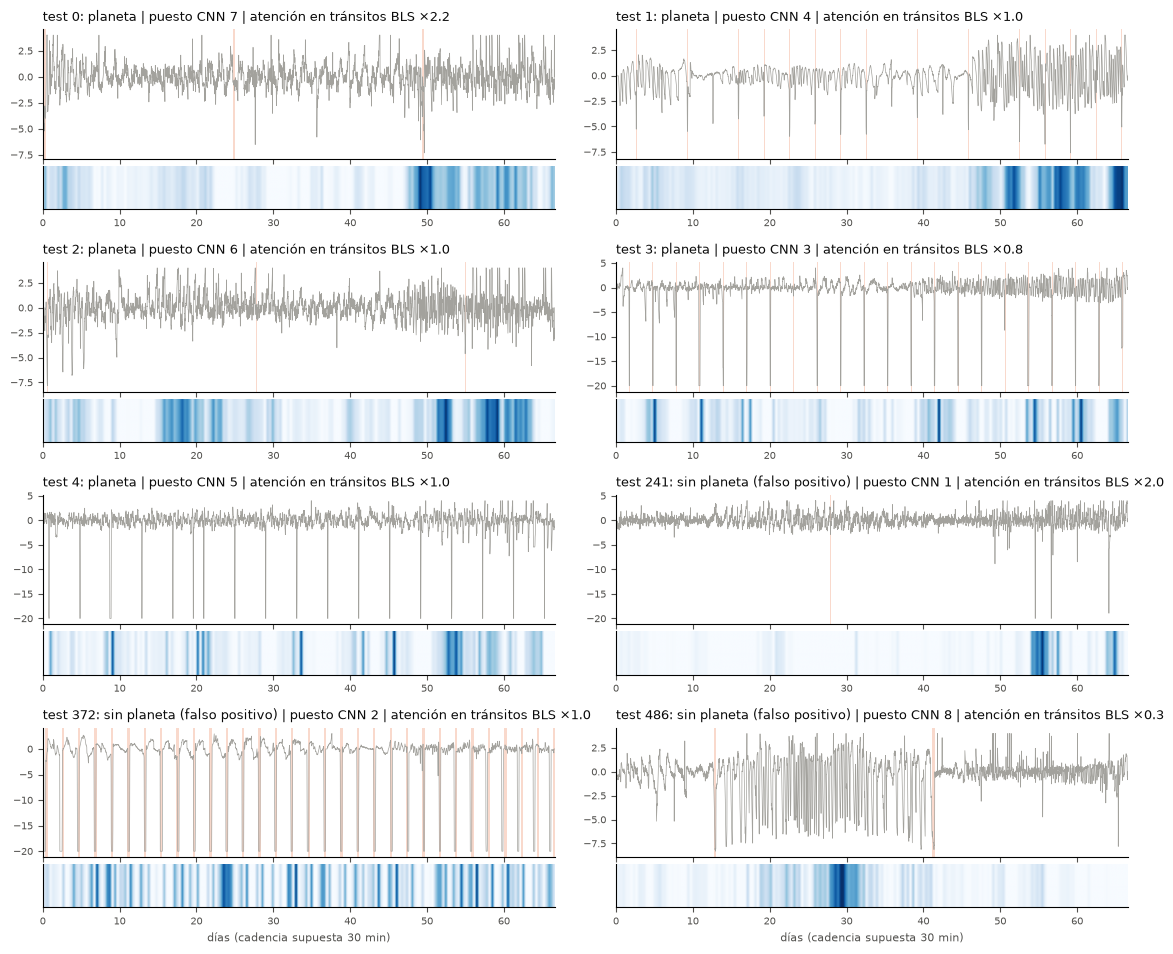

In [3]:
# Máscara de tránsitos del BLS y Grad-CAM para todas las estrellas del test
from joblib import Parallel, delayed
mascaras = Parallel(n_jobs=-1)(delayed(lambda z: bls_transit_mask(z)[0])(z) for z in Zte)
cam = grad_cam(cnn, Zte)
sal = smooth(saliency(cnn, Zte))
test['atencion_cam'] = [attention_on_transits(c, m) for c, m in zip(cam, mascaras)]
test['atencion_sal'] = [attention_on_transits(s, m) for s, m in zip(sal, mascaras)]

positivos = list(test.index[test.label == 1])
fp_top = list(test[test.label == 0].sort_values('p_cnn', ascending=False).index[:3])
t_dias = np.arange(Zte.shape[1]) / 48

fig = plt.figure(figsize=(14, 12))
gs = fig.add_gridspec(12, 2, height_ratios=[3, 1, 0.9] * 4, hspace=0.1, wspace=0.12)   # 3a fila: separador
for k, idx in enumerate(positivos + fp_top):
    fila, col = 3 * (k // 2), k % 2
    ax = fig.add_subplot(gs[fila, col])
    axc = fig.add_subplot(gs[fila + 1, col], sharex=ax)
    m = mascaras[idx]
    bordes = np.flatnonzero(np.diff(np.r_[0, m.astype(int), 0]))
    for a, b in zip(bordes[::2], bordes[1::2]):
        ax.axvspan(t_dias[a], t_dias[min(b, len(t_dias) - 1)], color=TRANSITO, alpha=0.25, lw=0)
    ax.plot(t_dias, np.clip(Zte[idx], -20, 5), color=GRIS, lw=0.5)
    tipo = 'planeta' if yte[idx] else 'sin planeta (falso positivo)'
    ax.set_title(f'test {idx}: {tipo} | puesto CNN {test.puesto_cnn[idx]} | '
                 f'atención en tránsitos BLS ×{test.atencion_cam[idx]:.1f}', fontsize=9, color='#0b0b0b', loc='left')
    axc.imshow(cam[idx][None, :], aspect='auto', cmap='Blues', extent=[t_dias[0], t_dias[-1], 0, 1], vmin=0, vmax=1)
    axc.set_yticks([])
    plt.setp(ax.get_xticklabels(), visible=False)
    for a in (ax, axc):
        a.tick_params(labelsize=7, colors=TEXTO)
        for s in ['top', 'right']:
            a.spines[s].set_visible(False)
    if k >= 6:
        axc.set_xlabel('días (cadencia supuesta 30 min)', fontsize=8, color=TEXTO)
plt.savefig('../results/08_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()

**Concentración de la atención en los tránsitos del BLS** (×1 = la CNN no mira los tránsitos del BLS más que el
resto de la curva). Se compara entre planetas, los falsos positivos más fuertes y el resto de las estrellas.

In [4]:
grupo = np.where(test.label == 1, 'planetas (5)', np.where(test.index.isin(test[test.label == 0]
                 .sort_values('p_cnn', ascending=False).index[:20]), 'top-20 falsos positivos', 'resto sin planeta'))
test['grupo'] = grupo
test.groupby('grupo')[['atencion_cam', 'atencion_sal', 'bls_snr']].median().round(2)

,atencion_cam,atencion_sal,bls_snr
grupo,,,
planetas (5),1.03,1.64,31.06
resto sin planeta,1.03,1.47,13.28
top-20 falsos positivos,1.30,1.74,15.36


## 2. ¿Qué features usa el Random Forest?

Importancia por permutación: cuánto cae el PR-AUC del fold de validación al desordenar una feature (rompe su
relación con la etiqueta). Se calcula en los 5 folds de validación, no sobre el entrenamiento, para medir lo que
generaliza y no lo que memoriza.

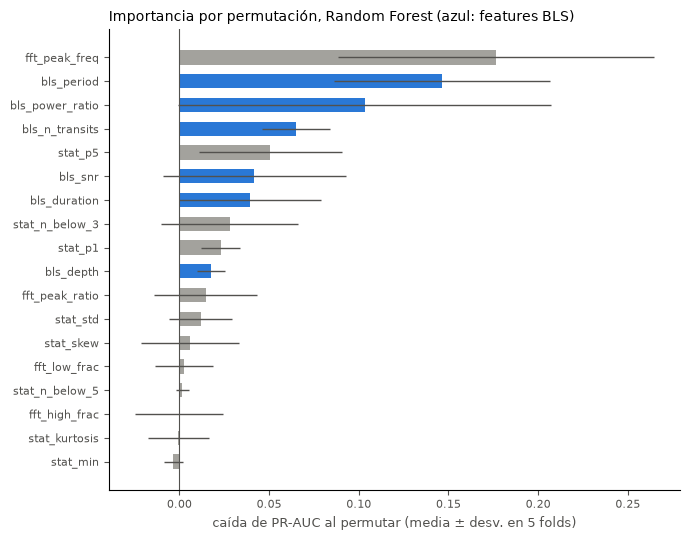

,mean,std
fft_peak_freq,0.177,0.088
bls_period,0.146,0.060
bls_power_ratio,0.103,0.104
bls_n_transits,0.065,0.019
stat_p5,0.051,0.040
bls_snr,0.042,0.051
bls_duration,0.039,0.040
stat_n_below_3,0.028,0.038
stat_p1,0.023,0.011
bls_depth,0.017,0.008


In [5]:
Xf = F_train[cols].to_numpy()
imp = []
for k, (tr, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=0).split(Xf, ytr)):
    m = make_random_forest().fit(Xf[tr], ytr[tr])
    r = permutation_importance(m, Xf[va], ytr[va], scoring='average_precision', n_repeats=10, random_state=k, n_jobs=-1)
    imp.append(r.importances_mean)
imp = pd.DataFrame(imp, columns=cols)
resumen_imp = imp.agg(['mean', 'std']).T.sort_values('mean')

fig, ax = plt.subplots(figsize=(7, 5.5))
yy = np.arange(len(resumen_imp))
colores = [ACENTO if c.startswith('bls_') else GRIS for c in resumen_imp.index]
ax.barh(yy, resumen_imp['mean'], xerr=resumen_imp['std'], color=colores, height=0.6,
        error_kw=dict(ecolor=TEXTO, lw=1))
ax.set_yticks(yy, resumen_imp.index, fontsize=8)
ax.axvline(0, color=TEXTO, lw=0.8)
ax.set_xlabel('caída de PR-AUC al permutar (media ± desv. en 5 folds)', fontsize=9, color=TEXTO)
ax.set_title('Importancia por permutación, Random Forest (azul: features BLS)', fontsize=10, loc='left')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=TEXTO, labelsize=8)
plt.tight_layout()
plt.savefig('../results/08_importancia_rf.png', dpi=150, bbox_inches='tight')
plt.show()
resumen_imp[::-1].round(3)

## 3. Análisis de errores (predicciones fuera de fold, 37 positivos del entrenamiento)

Cada estrella se ordena por su puntaje fuera de fold (promedio de las 5 repeticiones en el RF). Un planeta se
considera detectado si supera el umbral elegido en CV.

In [6]:
oof_rf = np.load(ABL / 'rf_base_oof.npy').mean(axis=0)
err = F_train[['bls_snr', 'bls_depth', 'bls_period', 'bls_n_transits', 'bls_power_ratio', 'stat_min']].copy()
err['label'] = ytr
err['p_rf'] = oof_rf
err['puesto_rf'] = puesto(oof_rf)
err['detectado_rf'] = oof_rf >= umbral['rf']
if 'cnn' in umbral:
    oof_cnn = np.load(ABL / f'{CNN_NOMBRE}_oof.npy').mean(axis=0)
    err['p_cnn'] = oof_cnn
    err['puesto_cnn'] = puesto(oof_cnn)
    err['detectado_cnn'] = oof_cnn >= umbral['cnn']

pos = err[err.label == 1].sort_values('p_rf', ascending=False)
print('planetas detectados por el RF:', pos.detectado_rf.sum(), 'de', len(pos))
if 'cnn' in umbral:
    print('por la CNN:', pos.detectado_cnn.sum(), '| por ambos:', (pos.detectado_rf & pos.detectado_cnn).sum(),
          '| solo CNN:', (~pos.detectado_rf & pos.detectado_cnn).sum(), '| ninguno:', (~pos.detectado_rf & ~pos.detectado_cnn).sum())
pos.round(3)

planetas detectados por el RF: 13 de 37


,bls_snr,bls_depth,bls_period,bls_n_transits,bls_power_ratio,stat_min,label,p_rf,puesto_rf,detectado_rf
35,213.872,24.672,4.179,15,4.042,-38.479,1,0.689,1,True
5,18.726,3.919,6.805,9,2.389,-6.658,1,0.548,2,True
11,169.114,15.200,2.536,26,5.165,-37.439,1,0.515,3,True
18,45.069,4.927,7.641,8,3.690,-9.098,1,0.494,4,True
19,28.864,2.103,4.700,14,3.748,-4.736,1,0.456,5,True
1,62.591,6.073,2.910,22,3.773,-14.178,1,0.445,6,True
31,14.941,2.614,8.950,7,2.055,-6.055,1,0.321,8,True
15,17.008,3.485,14.242,4,2.272,-5.322,1,0.314,10,True
29,14.565,2.140,6.550,10,1.899,-4.400,1,0.298,12,True
30,24.509,2.281,1.395,47,4.631,-6.235,1,0.297,13,True


In [7]:
# Planetas detectados vs. no detectados por el RF, y falsos positivos: ¿en qué se diferencian?
fp = err[(err.label == 0) & err.detectado_rf]
comp = pd.concat({
    'planetas detectados': pos[pos.detectado_rf].median(numeric_only=True),
    'planetas no detectados': pos[~pos.detectado_rf].median(numeric_only=True),
    f'falsos positivos ({len(fp)})': fp.median(numeric_only=True),
    'sin planeta (todas)': err[err.label == 0].median(numeric_only=True),
}, axis=1)
comp.loc[['bls_snr', 'bls_depth', 'bls_period', 'bls_n_transits', 'bls_power_ratio', 'stat_min']].round(3)

,planetas detectados,planetas no detectados,falsos positivos (4),sin planeta (todas)
bls_snr,27.426,18.637,26.381,13.008
bls_depth,3.485,2.857,1.961,2.164
bls_period,5.684,22.145,4.415,22.578
bls_n_transits,11.000,2.500,21.000,2.000
bls_power_ratio,3.690,1.640,2.410,1.648
stat_min,-6.991,-8.748,-8.880,-6.573


## 4. ¿Hay sesgo por campaña? Una fuga de información en el dataset

Más del 99 % de las estrellas vienen de la campaña 3 y los positivos extra de otras campañas, procesadas aparte. Se
buscan huellas de ese origen que no tengan que ver con el planeta. Primero, la más simple: el nivel del flujo crudo.

In [8]:
from sklearn.metrics import precision_score, recall_score
filas = []
for nombre, X, y in [('entrenamiento', Xtr, ytr), ('test', Xte, yte)]:
    cero = np.median(X, axis=1) == 0
    regla = (~cero).astype(int)          # regla trivial: "si la mediana cruda no es exactamente 0, tiene planeta"
    filas.append({'conjunto': nombre,
                  'sin planeta con mediana = 0': f'{(cero & (y == 0)).sum()}/{(y == 0).sum()}',
                  'con planeta con mediana = 0': f'{(cero & (y == 1)).sum()}/{y.sum()}',
                  'regla trivial: recall': recall_score(y, regla), 'regla trivial: precisión': precision_score(y, regla)})
pd.DataFrame(filas).round(2)

,conjunto,sin planeta con mediana = 0,con planeta con mediana = 0,regla trivial: recall,regla trivial: precisión
0,entrenamiento,5050/5050,6/37,0.84,1.0
1,test,565/565,2/5,0.60,1.0


**Todas** las estrellas sin planeta tienen la mediana del flujo crudo exactamente en 0 (fueron centradas al
armar el dataset), pero la mayoría de las estrellas con planeta no. La regla "mediana distinta de 0 ⇒ planeta" no
mira ningún tránsito y aun así supera a todos nuestros modelos. Es una **fuga de información**: cualquier modelo
entrenado sobre el flujo crudo sin centrar (como muchos notebooks públicos de este dataset) puede aprovecharla.

Otras huellas del origen, sobre la curva cruda: un RF con solo propiedades ajenas al planeta.

In [9]:
from scipy.ndimage import median_filter
tendencia = median_filter(Xtr, size=(1, 101), mode='nearest')
nuisance = pd.DataFrame({
    'log_nivel': np.log10(np.abs(np.median(Xtr, axis=1)) + 1),
    'log_ruido': np.log10(robust_std(Xtr - tendencia) + 1e-9),
    'log_tendencia': np.log10(tendencia.std(axis=1) + 1e-9),
    'frac_repetidos': [1 - len(np.unique(x)) / len(x) for x in Xtr],
})
res_nui = {}
for nombre, cs in [('las 4 juntas', list(nuisance.columns)), *[(c, [c]) for c in nuisance.columns]]:
    f, _ = repeated_cv(make_random_forest, nuisance[cs].to_numpy(), ytr, n_splits=5, n_repeats=2)
    res_nui[nombre] = summarize_cv(f).loc['pr_auc', 'mean']
print('PR-AUC (CV 5x2) de un RF con features ajenas al planeta (azar 0,007; 18 features físicas 0,394):')
print(pd.Series(res_nui).round(3).to_string())
nuisance.groupby(ytr).median().rename(index={0: 'sin planeta', 1: 'con planeta'}).round(3)

PR-AUC (CV 5x2) de un RF con features ajenas al planeta (azar 0,007; 18 features físicas 0,394):
las 4 juntas      0.843
log_nivel         0.842
log_ruido         0.016
log_tendencia     0.009
frac_repetidos    0.016


,log_nivel,log_ruido,log_tendencia,frac_repetidos
sin planeta,0.000,1.286,1.218,0.193
con planeta,0.009,1.492,1.832,0.135


Casi todo lo explica el nivel. Ruido, tendencia y fracción de valores repetidos difieren algo entre clases pero
no separan por sí solos.

**¿Nos afecta?** Nuestro preprocesamiento resta la mediana móvil y luego la mediana global, así que el nivel
desaparece. Para descartar rastros indirectos, se entrena un RF solo con el **lado de arriba** de la curva
preprocesada (percentiles altos, dispersión de los valores positivos): un tránsito solo baja el brillo, así que eso no
contiene información del planeta, pero sí la tendría del origen si quedara.

In [10]:
def lado_arriba(Z):
    up = np.where(Z > 0, Z, 0)
    q = Z.shape[1] // 4
    return pd.DataFrame({'p90': np.percentile(Z, 90, axis=1), 'p99': np.percentile(Z, 99, axis=1),
                         'std_arriba': up.std(axis=1), 'std_arriba_primer_cuarto': up[:, :q].std(axis=1),
                         'std_arriba_ultimo_cuarto': up[:, -q:].std(axis=1)})

print('mediana de las curvas preprocesadas, máx |.|:', np.abs(np.median(Ztr, axis=1)).max())
A_tr, A_te = lado_arriba(Ztr), lado_arriba(Zte)
f, _ = repeated_cv(make_random_forest, A_tr.to_numpy(), ytr, n_splits=5, n_repeats=5)
print('RF con solo el lado de arriba de la curva preprocesada, CV 5x5: PR-AUC %.3f ± %.3f' % tuple(summarize_cv(f).loc['pr_auc']))
m_up = make_random_forest().fit(A_tr.to_numpy(), ytr)
print('en test: PR-AUC %.3f' % compute_metrics(yte, m_up.predict_proba(A_te.to_numpy())[:, 1])['pr_auc'])

mediana de las curvas preprocesadas, máx |.|: 0.0


RF con solo el lado de arriba de la curva preprocesada, CV 5x5: PR-AUC 0.018 ± 0.010


en test: PR-AUC 0.012


## Conclusiones

**1. La CNN no se apoya de forma consistente en los tránsitos que encuentra el BLS.** La concentración del Grad-CAM en
los tránsitos del BLS es ×1,0 (mediana) en los 5 planetas del test: la misma que en estrellas sin planeta. En los
planetas con tránsitos profundos y claros (test 3 y 4) la red marca varias caídas, pero también tramos sin tránsito;
en los de señal débil (test 0, 1, 2) mira sobre todo los tramos más ruidosos del final de la curva. Esos tramos
ruidosos no son una huella del origen de los datos (sección 4: el lado de arriba de la curva preprocesada no
predice nada), así que la red parece responder a "zonas con caídas fuertes" más que a la repetición del tránsito.
Los falsos positivos lo confirman:
- **test 241**: tres caídas profundas aisladas, no periódicas, y la CNN lo pone primero. Es coherente con la hipótesis del informe
  de avance: el *global max pooling* detecta caídas pero no su repetición.
- **test 372**: caídas periódicas muy profundas (~-20σ), probablemente una binaria eclipsante. Engaña también al BLS:
  es un falso positivo astrofísico, que ningún método basado solo en caídas puede distinguir sin más información.
- **test 486**: un tramo de oscilación de gran amplitud.

Limitaciones: el Grad-CAM de la última capa tiene una resolución de ~16 puntos (~8 h) y son solo 5 planetas; la
lectura es cualitativa.

**2. El Random Forest usa sobre todo la frecuencia del pico de la FFT y el período, el contraste y el número de
tránsitos del BLS.** Prefiere estrellas con un período corto y muchos tránsitos. Las desviaciones entre folds son
grandes, así que el orden exacto no es confiable.

**3. Los planetas que se escapan son los que el BLS no logra "enganchar".** Con el umbral elegido en CV, el RF
detecta 13 de 37 planetas fuera de fold. Los detectados tienen un período BLS mediano de 5,7 d, ~11 tránsitos y
contraste 3,7. Los no detectados tienen 22 d, ~2–3 tránsitos y contraste 1,6, prácticamente lo mismo que una estrella sin
planeta típica (22,6 d, 2 tránsitos, 1,65). Para esos planetas el BLS eligió un período largo espurio en vez de
la repetición real, así que el clasificador no tiene con qué distinguirlos: **el cuello de botella es la extracción
de features, no el clasificador**. Es coherente con la ablación (notebook 07): limitar el período máximo para exigir
más repeticiones mejora el resultado. Los falsos positivos del RF tienen muchas caídas periódicas (mediana de 21) con
SNR alto, típicas de binarias eclipsantes o estrellas variables.

**4. El dataset tiene una fuga de información.** Las 5.615 estrellas sin planeta (train y test) tienen la mediana
del flujo crudo exactamente en 0; 31 de 37 y 3 de 5 estrellas con planeta no. La regla trivial "mediana ≠ 0 ⇒
planeta" logra recall 0,84 con precisión 1,0 en el entrenamiento y 0,60 / 1,0 en el test, sin mirar ningún tránsito
y mejor que cualquier modelo de este trabajo. Consecuencias:
- Cifras publicadas sobre este dataset, como el 99,62 % de *accuracy* de Priyadarshini y Puri, o las de notebooks
  que trabajan sobre el flujo crudo, no son comparables a las nuestras: un modelo sobre la curva sin centrar puede
  aprender esta regla.
- **Nuestro pipeline es inmune:** el preprocesamiento centra todas las curvas (mediana 0 en todas) y un RF con solo
  el lado de arriba de la curva preprocesada no predice nada (PR-AUC 0,018 en CV y 0,012 en test, frente a 0,007 del
  azar). Nuestros resultados, más modestos, miden la detección de tránsitos y no el origen de los datos.
